# Final Model Evaluation

## Objective

Evaluate the selected Logistic Regression pipeline on the
independent test dataset.

The model was selected using training data and cross-validation.

The test dataset contains 400 observations and has not been
used during training or hyperparameter optimization.

This evaluation measures dataset classification performance,
not clinical validity.

In [2]:
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split

final_pipeline = joblib.load(
    "../models/final_logistic_regression_pipeline.joblib"
)

print("Model loaded successfully!")
print("Pipeline steps:", list(final_pipeline.named_steps.keys()))

df = pd.read_csv("../data/raw/student_mental_health.csv")

X = df.drop(columns=["Student_ID", "Mental_Health_Risk"])

y = df["Mental_Health_Risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Test features:", X_test.shape)
print("Test labels:", y_test.shape)

Model loaded successfully!
Pipeline steps: ['preprocessing', 'classifier']
Test features: (400, 15)
Test labels: (400,)


In [3]:
y_pred = final_pipeline.predict(X_test)

In [4]:
print("Number of predictions:", len(y_pred))

print("First 5 predictions:", y_pred[:5])

Number of predictions: 400
First 5 predictions: ['High' 'Medium' 'Medium' 'High' 'High']


In [5]:
from sklearn.metrics import accuracy_score

test_accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", test_accuracy)

Test Accuracy: 0.755


In [7]:
correct_predictions = accuracy_score(
    y_test,
    y_pred,
    normalize=False
)

incorrect_predictions = len(y_test) - correct_predictions

In [8]:
print("Total Test Observations:", len(y_test))

print("Correct Predictions:", correct_predictions)

print("Incorrect Predictions:", incorrect_predictions)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

Total Test Observations: 400
Correct Predictions: 302.0
Incorrect Predictions: 98.0
Test Accuracy: 75.5 %


In [10]:
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_pred,
    digits=3
)

print(report)

              precision    recall  f1-score   support

        High      0.812     0.824     0.818       136
         Low      0.817     0.811     0.814       132
      Medium      0.634     0.629     0.631       132

    accuracy                          0.755       400
   macro avg      0.754     0.754     0.754       400
weighted avg      0.755     0.755     0.755       400



In [11]:
from sklearn.metrics import confusion_matrix

labels = ["High", "Low", "Medium"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

print(cm)

[[112   0  24]
 [  1 107  24]
 [ 25  24  83]]


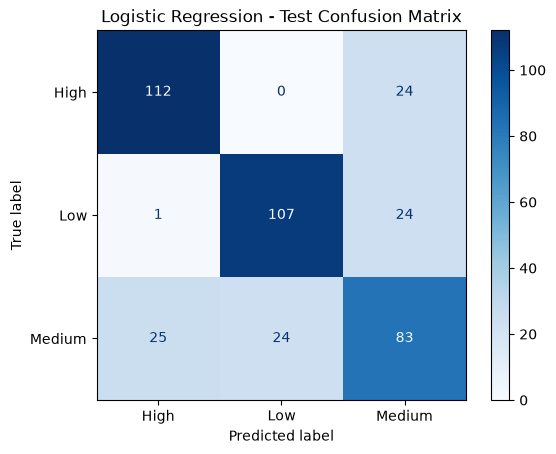

In [12]:
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

display_matrix.plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression - Test Confusion Matrix")

plt.show()

In [13]:
y_proba = final_pipeline.predict_proba(X_test)

print("Probability shape:", y_proba.shape)

print("Class order:", final_pipeline.classes_)

Probability shape: (400, 3)
Class order: ['High' 'Low' 'Medium']


In [14]:
from sklearn.metrics import roc_auc_score

test_roc_auc = roc_auc_score(
    y_test,
    y_proba,
    multi_class="ovr",
    average="macro",
    labels=final_pipeline.classes_
)

print("Test ROC-AUC:", round(test_roc_auc, 4))

Test ROC-AUC: 0.914


In [16]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

final_metrics = {
    "accuracy": accuracy_score(y_test, y_pred),

    "precision_macro": precision_score(
        y_test, y_pred, average="macro"
    ),

    "recall_macro": recall_score(
        y_test, y_pred, average="macro"
    ),

    "f1_macro": f1_score(
        y_test, y_pred, average="macro"
    ),

    "roc_auc_ovr_macro": test_roc_auc,

    "test_samples": len(y_test)
}

In [17]:
metrics_df = pd.DataFrame([final_metrics])

display(metrics_df.round(4))

,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr_macro,test_samples
0,0.755,0.754,0.7543,0.7541,0.914,400


In [19]:
import json

evaluation_results = {
    "model": "Logistic Regression",
    "test_samples": int(final_metrics["test_samples"]),
    "accuracy": float(final_metrics["accuracy"]),
    "precision_macro": float(final_metrics["precision_macro"]),
    "recall_macro": float(final_metrics["recall_macro"]),
    "f1_macro": float(final_metrics["f1_macro"]),
    "roc_auc_ovr_macro": float(final_metrics["roc_auc_ovr_macro"]),
    "labels": labels,
    "confusion_matrix": cm.tolist(),
    "classification_report": classification_report(
        y_test,
        y_pred,
        output_dict=True
    )
}

metrics_path = "../reports/final_evaluation.json"

with open(metrics_path, "w", encoding="utf-8") as file:
    json.dump(evaluation_results, file, indent=4)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


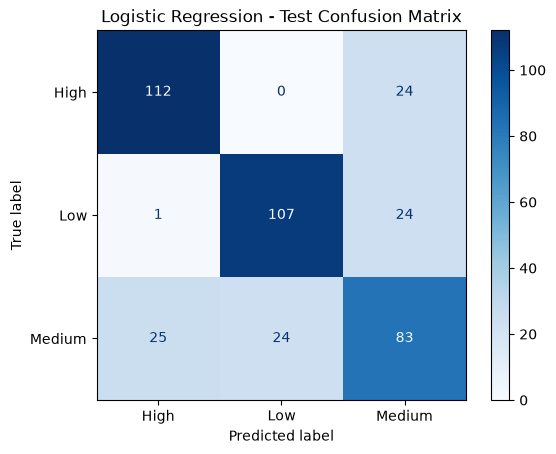

In [20]:
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

display_matrix.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression - Test Confusion Matrix")

plt.savefig(
    "../reports/figures/test_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## Final Evaluation Conclusions

### 1. Selected Model

Logistic Regression was selected based on cross-validation
performance during model development and optimization.

Final configuration:
- Model: Logistic Regression
- Regularization parameter C: 1
- Preprocessing: Median imputation, standardization,
  categorical imputation, and one-hot encoding.

### 2. Test Dataset

The independent test dataset contains 400 observations,
representing 20% of the original dataset.

This dataset was not used during model training,
hyperparameter optimization, or model selection.

### 3. Final Performance

- Test Accuracy: 75.50%
- Macro Precision: 0.7540
- Macro Recall: 0.7543
- Macro F1: 0.7541
- Multiclass ROC-AUC (OvR): 0.9140

### 4. Generalization

The model achieved:

- Cross-validation Accuracy: 75.19%
- Test Accuracy: 75.50%
- Cross-validation Macro F1: 0.7513
- Test Macro F1: 0.7541

The similar results suggest reasonable generalization
to the independent test dataset.

### 5. Error Analysis

Class-specific F1-scores:

- High: 0.818
- Low: 0.814
- Medium: 0.631

The Medium category was the most difficult to classify.

Of the 98 incorrect predictions, 97 involved
the Medium category.

This suggests considerable overlap or ambiguity between
Medium and the other categories.

### 6. Limitations

- The dataset contains only 2,000 observations.
- Evaluation used one independent test split.
- Cross-validation used three folds.
- The model has difficulty distinguishing Medium.
- The clinical validity of the dataset labels was not verified.
- Performance on other student populations is unknown.
- No additional tuning was performed using test results.

### 7. Final Decision

Retain Logistic Regression as the selected classification model.

The complete preprocessing and classification pipeline
has been saved using Joblib.

Evaluation metrics and the confusion matrix have been
saved for the Streamlit application.

This model is strictly educational and must not be
used for medical diagnosis, clinical screening,
or real-world decisions about students.